# Análisis de conceptos candidatos a puentes entre emociones

Análisis numérico de los conceptos obtenidos en los caminos de ConceptNet. 
El propósito es no saturar la ipynb analysis para trabajar en limpio. 
Para le 06/11/26 sólo se trabajarán las palabras obtenidas entre los conjuntos de altamente prototípcas de felicidad y tristeza ya filtrados con EmoPro y ConceptNet para eliminar los conceptos emocionales.
___
### To do:
- Recuperar caminos por palabras particulares del top 50
- Analisar los conceptos y los caminos para determinar direccion de relaciones
- Buscar forma de hacer conteo de relaciones inmediatas de conceptos candidatos y la dirección de relaciones inmediatas
- Revisar cada camino por concepto puente candidato y revisar su posición relativa en el camino (centro, felicidad o tristeza) y guardar los conteos finales de cada uno
- Pensar en cómo vincular las palabras con escenarios de appraisal y mecanismos de afrontamiento

In [4]:
import pandas as pd
import pickle
import csv
import seaborn as sns

from matplotlib import pyplot as plt


In [5]:
help(csv.reader)

Help on built-in function reader in module _csv:

reader(...)
    csv_reader = reader(iterable [, dialect='excel']
                            [optional keyword args])
        for row in csv_reader:
            process(row)
    
    The "iterable" argument can be any object that returns a line
    of input for each iteration, such as a file object or a list.  The
    optional "dialect" parameter is discussed below.  The function
    also accepts optional keyword arguments which override settings
    provided by the dialect.
    
    The returned object is an iterator.  Each iteration returns a row
    of the CSV file (which can span multiple input lines).



In [6]:
candidatos_esp = []
candidatos_ing = []
todos = []
with open('puentes_candidatos/candidatos_esp_2.csv', 'r') as f:
   reader = csv.reader(f)
   for row in reader:
       candidatos_esp.append(row[0])
with open('puentes_candidatos/candidatos_ing_2.csv', 'r') as f:
   reader = csv.reader(f)
   for row in reader:
       candidatos_ing.append(row[0])

with open('puentes_candidatos/conteos_conceptos.pickle', 'rb') as f:
    conteos = pickle.load(f)
    
with open('puentes_candidatos/finales_limpios.csv', 'r') as f:
    reader = csv.reader(f)
    for row in reader:
       todos.append(row)

In [9]:
len(todos)

10643

In [3]:
len(candidatos_ing)

8978

In [7]:
conteos_esp = {}
conteos_ing = {}


for p in candidatos_esp:
    conteos_esp[p] = conteos[p]


for w in candidatos_ing:
    conteos_ing[w]=conteos[w]



In [8]:
def graficador(datos:list, idioma:str) -> None:
    ordenadas = sorted(datos.items(), key = lambda x: x[1], reverse=True)
    frecuencias = [frec for p,frec in ordenadas]
    rank = range(1, len(frecuencias) + 1)
    plt.figure(figsize=(9,5))
    plt.plot(rank, frecuencias, color='r')

    plt.yscale('log')
    plt.xscale('log')
    plt.xlabel('Rangos de palabras (Log)')
    plt.ylabel('Frecuencias (Log)')
    plt.title(f'Distribución de Frecuencias (Ley Zipf){idioma}')
    plt.grid(True, which='both', linestyle = '--', alpha = 0.5)
    plt.show()

    plt.figure(figsize=(9,5))
    sns.histplot(frecuencias, bins= 50, kde=True, color='teal')
    plt.xlabel('Frecuencia de la palabra')
    plt.ylabel('Cantidad de palabras')
    plt.title(f'Distribución de Frecuencias en caminos en {idioma}')
    plt.show()
    
    top_n = 50
    top_w = ordenadas[:top_n]

    p, f = zip(*top_w)

    plt.figure(figsize=(13, 10))
    sns.barplot(x=list(f), y=list(p), hue=list(p), palette='viridis', legend=False)
    plt.xlabel('Frecuencia')
    plt.ylabel('Palabra')
    plt.title(f'Top {top_n} palabras más frecuentes en {idioma}')
    plt.show()

    return top_w


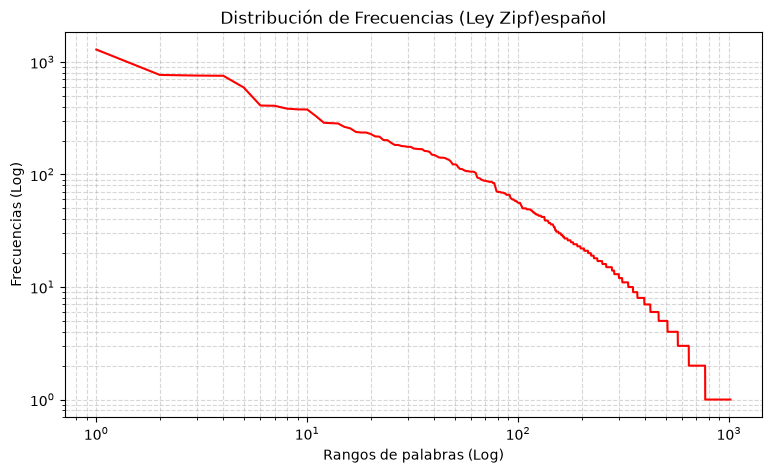

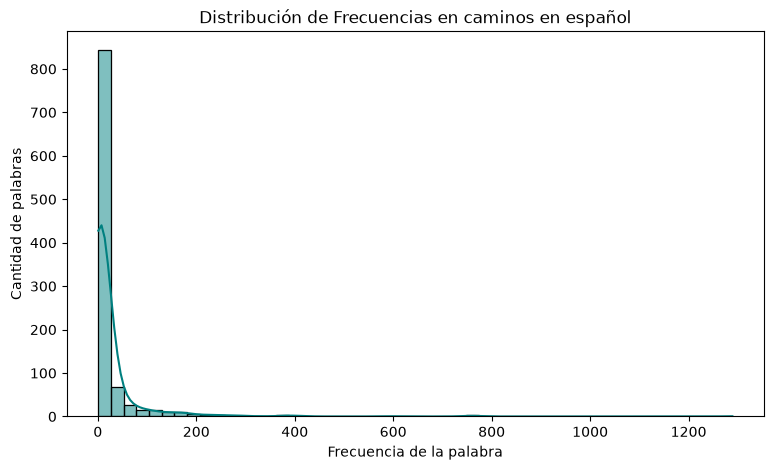

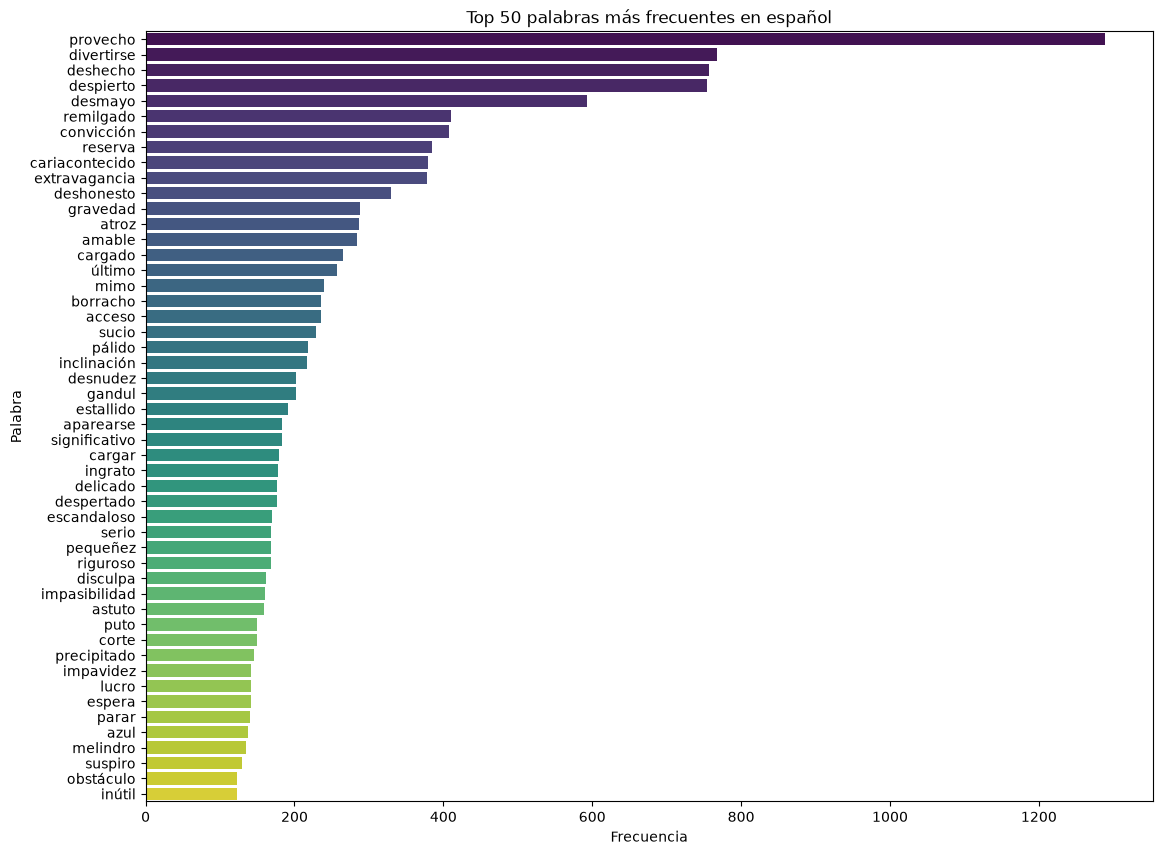

In [9]:
id = 'español'
top_conteo_es = graficador(conteos_esp, id)

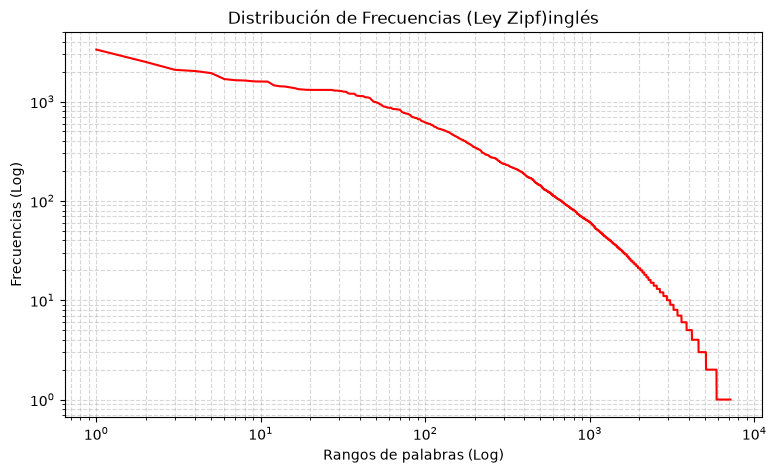

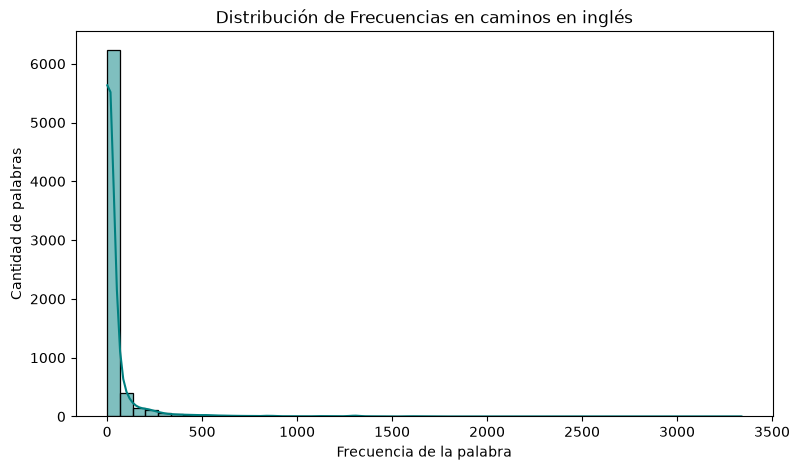

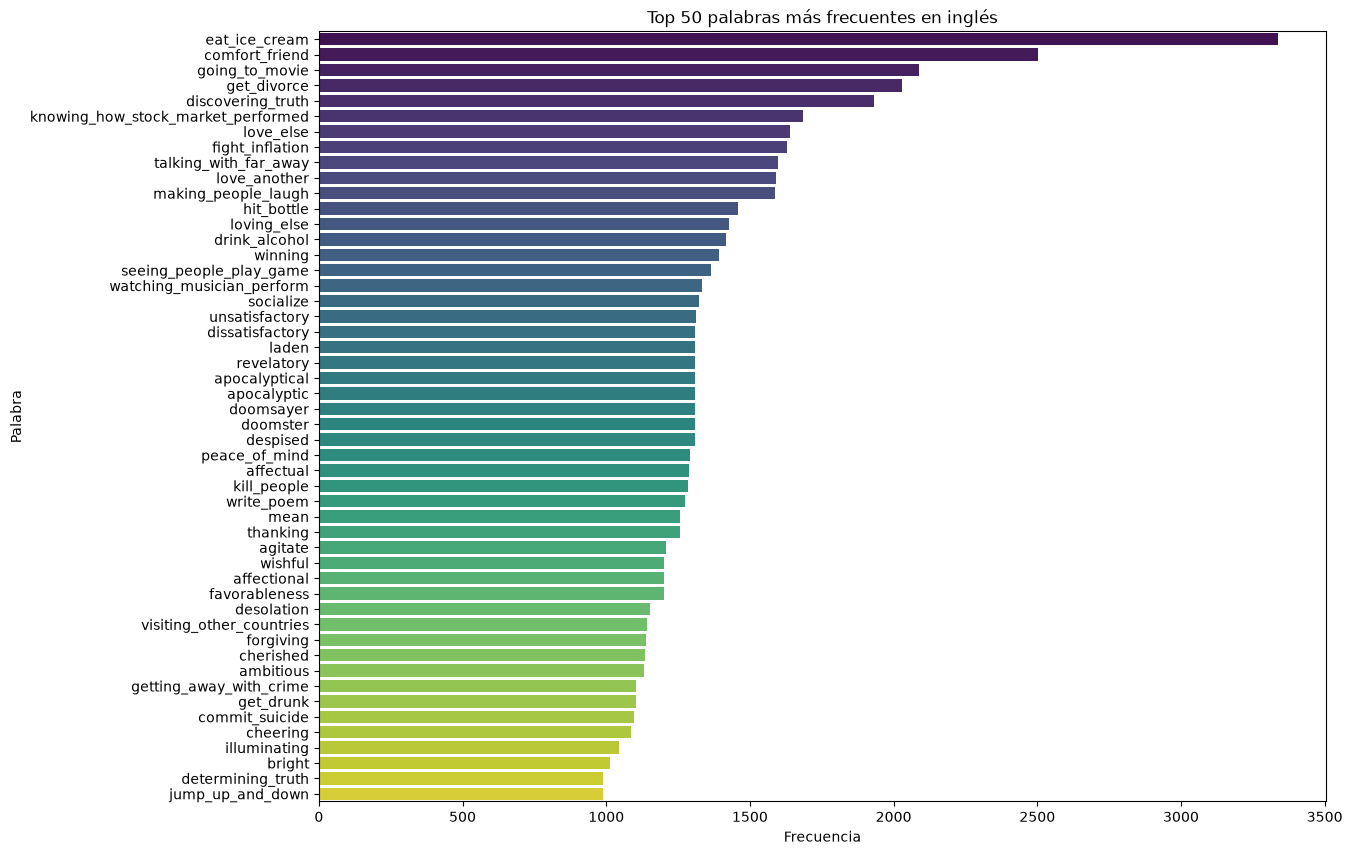

In [10]:
id = 'inglés'
top_conteo_in = graficador(conteos_ing, id)

In [12]:
palabras_candidatas_esp, c = zip(*top_conteo_es)
palabras_candidatas_esp = set(palabras_candidatas_esp)

palabras_candidatas_ing, cuenta = zip(*top_conteo_in)
palabras_candidatas_ing = set(palabras_candidatas_ing)

In [13]:
with open('caminos_obtenidos/implicatura_fA_tA.pickle', 'rb') as f:
    caminosFaTa = pickle.load(f)

In [16]:
len(palabras_candidatas_ing)

50

In [18]:
len(caminosFaTa)

15720

In [14]:
caminosC_candidatos = {}

for k in caminosFaTa.keys():
    for camino in caminosFaTa[k]:
        l = []
        camino = camino.split(' ')
        for c in camino:
            if c in palabras_candidatas_ing:
                l.append(camino)
        if len(l) > 0:
            caminosC_candidatos[k] = l

In [15]:
len(caminosC_candidatos)

10471

In [17]:
caminosC_candidatos

{('admiración',
  'abatido'): [['admiración',
   '--Synonym-->',
   'wonder',
   '(en)',
   '<--Causes--',
   'seeing_art',
   '(en)',
   '--Causes-->',
   'enjoy',
   '(en)',
   '<--HasPrerequisite--',
   'eat_ice_cream',
   '(en)',
   '--MotivatedByGoal-->',
   'depressed',
   '(en)',
   '--Synonym-->',
   'abatido',
   '(es)']],
 ('admiración',
  'aburrirse'): [['admiración',
   '--Synonym-->',
   'wonder',
   '(en)',
   '<--Causes--',
   'talking_with_far_away',
   '(en)',
   '--HasSubevent-->',
   'having_conversation',
   '(en)',
   '--Causes-->',
   'anger',
   '(en)',
   '<--Synonym--',
   'enfadar',
   '(es)',
   '<--Synonym--',
   'cabrear',
   '(es)',
   '--Synonym-->',
   'aburrirse',
   '(es)']],
 ('admiración',
  'afligido'): [['admiración',
   '--Synonym-->',
   'astonishment',
   '(en)',
   '<--Causes--',
   'seeing_new',
   '(en)',
   '<--Causes--',
   'going_to_movie',
   '(en)',
   '--HasSubevent-->',
   'cry',
   '(en)',
   '--MotivatedByGoal-->',
   'distraught',
 

In [20]:
caminosC_candidatos[('admiración', 'abatido')]

[['admiración',
  '--Synonym-->',
  'wonder',
  '(en)',
  '<--Causes--',
  'seeing_art',
  '(en)',
  '--Causes-->',
  'enjoy',
  '(en)',
  '<--HasPrerequisite--',
  'eat_ice_cream',
  '(en)',
  '--MotivatedByGoal-->',
  'depressed',
  '(en)',
  '--Synonym-->',
  'abatido',
  '(es)']]